In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1" 
print(os.cpu_count())

144


In [2]:
import numpy as np
import math
import random as rand
import statistics
import matplotlib.pyplot as plt
from tqdm import tqdm

# Summarize the results

In [4]:
nq_list = [6,10,14,18,22,26,30]
num_train_list = [4000, 8000]
target_list = ["xy_corr_center", "xy_corr", "xxyy_nonlinear"]

for num_train in num_train_list:
    for target in target_list:
        #SK
        mean_list = []
        stdv_list = []
        for nq in nq_list:
            x = np.load(f"results_temp/sk_{target}_N={nq}_nt={num_train}_normalize.npy")
            mean_list.append(x[1])
            stdv_list.append(x[2])
        np.save(f"results/SK_ndep_{target}_nt={num_train}_normalize.npy", np.array([nq_list, mean_list, stdv_list]))

        #TESK
        mean_list = []
        stdv_list = []
        for nq in nq_list:
            x = np.load(f"results_temp/tesk_{target}_N={nq}_nt={num_train}_normalize.npy")
            mean_list.append(x[1])
            stdv_list.append(x[2])
        np.save(f"results/TESK_ndep_{target}_nt={num_train}_normalize.npy", np.array([nq_list, mean_list, stdv_list]))

# Results

## n-dependence

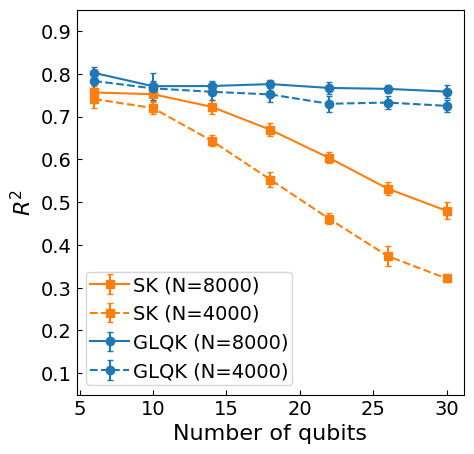

In [52]:
target = "xy_corr_center"
sk1 = np.load(f"results/SK_ndep_{target}_nt=8000_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=4000_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=8000_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=4000_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,0.95)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Number of qubits", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)
plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=8000)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=4000)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=4000)")
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=14, handletextpad=0.2, borderpad=0.2)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

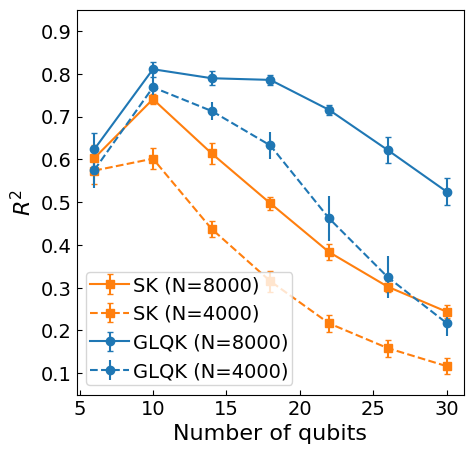

In [54]:
target = "xy_corr"
sk1 = np.load(f"results/SK_ndep_{target}_nt=8000_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=4000_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=8000_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=4000_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,0.95)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Number of qubits", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=8000)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=4000)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=4000)")
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

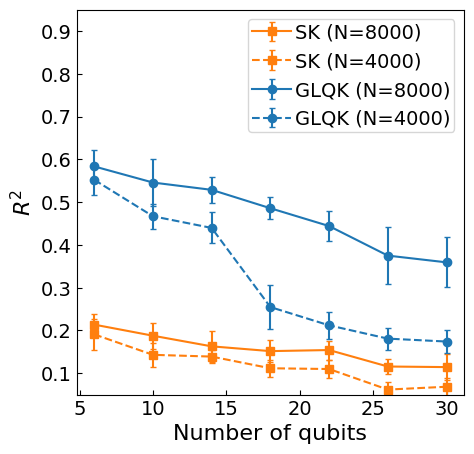

In [55]:
target = "xxyy_nonlinear"
sk1 = np.load(f"results/SK_ndep_{target}_nt=8000_normalize.npy")
sk2 = np.load(f"results/SK_ndep_{target}_nt=4000_normalize.npy")
tesk1 = np.load(f"results/TESK_ndep_{target}_nt=8000_normalize.npy")
tesk2 = np.load(f"results/TESK_ndep_{target}_nt=4000_normalize.npy")

plt.figure(figsize=(5,5))
plt.ylim(0.05,0.95)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Number of qubits", fontsize=16)
plt.ylabel(f"$R^2$", fontsize=16)

plt.errorbar(sk1[0], sk1[1], yerr=sk1[2], capsize=2, linestyle='solid', color='tab:orange', marker='s', label="SK (N=8000)")
plt.errorbar(sk2[0], sk2[1], yerr=sk2[2], capsize=2, linestyle='dashed', color='tab:orange', marker='s', label="SK (N=4000)")
plt.errorbar(tesk1[0], tesk1[1], yerr=tesk1[2], capsize=2, linestyle='solid', color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.errorbar(tesk2[0], tesk2[1], yerr=tesk2[2], capsize=2, linestyle='dashed', color='tab:blue', marker='o', label="GLQK (N=4000)")
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/ndep_{target}_normalize.pdf", bbox_inches="tight", pad_inches=0.1)

## scatter plots

In [56]:
N=30
num_train = 8000
num_test = 500

target = "xy_corr_center"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.13539194792205783


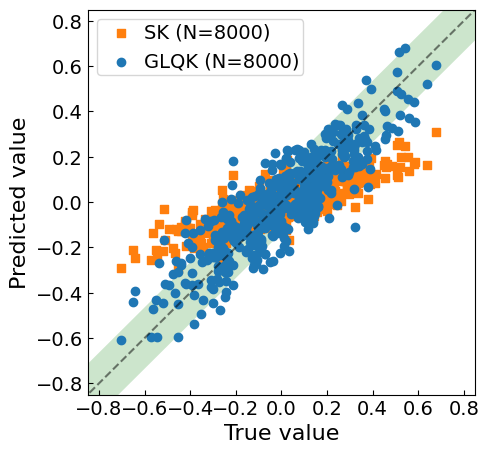

In [57]:
target = "xy_corr_center"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.85,0.85)
plt.ylim(-0.85,0.85)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=8000)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}.pdf", bbox_inches="tight", pad_inches=0.1)

In [58]:
N=30
num_train = 8000
num_test = 500

target = "xy_corr"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.13717715462147997


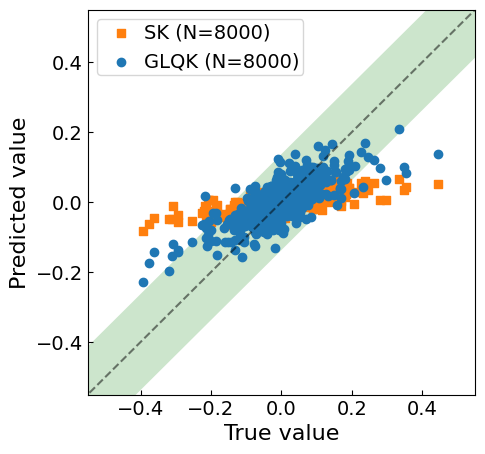

In [59]:
target = "xy_corr"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.55,0.55)
plt.ylim(-0.55,0.55)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=8000)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}.pdf", bbox_inches="tight", pad_inches=0.1)

In [60]:
N=30
num_train = 8000
num_test = 500

target = "xxyy_nonlinear"

filename = f'gram_matrix_N={N}/{target}.csv'
val = np.loadtxt(filename, delimiter=",", dtype=np.float64)

filename = f'gram_matrix_N={N}/cs_estimate_{target}.csv'
cs = np.loadtxt(filename, delimiter=",", dtype=np.float64)

# Using only test data
dif_list = val - cs
dif_list2 = dif_list[num_train:num_train+num_test]

dif = np.sqrt(np.sum((dif_list2)**2/len(dif_list2)))
print(dif)

0.050966732464234304


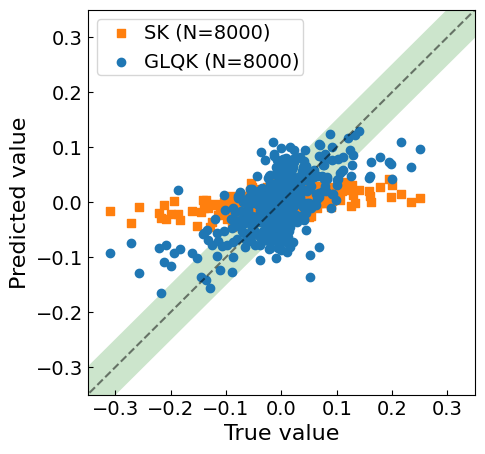

In [61]:
target = "xxyy_nonlinear"
sk = np.load(f"results/SK_scatter_{target}_N={N}_nt={num_train}.npy")
tesk = np.load(f"results/TESK_scatter_{target}_N={N}_nt={num_train}.npy")

x = np.linspace(-3,3, 10)

plt.figure(figsize=(5,5))

plt.xlim(-0.35,0.35)
plt.ylim(-0.35,0.35)

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("True value", fontsize=16)
plt.ylabel("Predicted value", fontsize=16)

plt.fill_between(x, x+dif, x-dif, color='green', linewidth=0, alpha=0.2)
plt.scatter(sk[0], sk[1], color='tab:orange', marker='s', label="SK (N=8000)")
plt.scatter(tesk[0], tesk[1], color='tab:blue', marker='o', label="GLQK (N=8000)")
plt.plot(x,x, color="black", linestyle='dashed', alpha=0.5)
plt.legend(ncol=2, loc=(0.0,1.01), fontsize=12)
plt.legend(fontsize=14, handletextpad=0.2, borderpad=0.2, columnspacing=1.0)

plt.savefig(f"figs/scatter_{target}.pdf", bbox_inches="tight", pad_inches=0.1)